# Reproduction: likelihood-based banana disease detection with a conditional normalizing flow

**Paper:** A. Prusokiene, A. Prusokas, R. Retkute, *"Vision normalizing flows for the probability-informed detection of banana diseases from in-field images"*, Front. Plant Sci. 17:1937900 (2026). DOI: [10.3389/fpls.2026.1937900](https://doi.org/10.3389/fpls.2026.1937900)

**Author code:** [Geofly/vision-normalizing-flows-for-banana-diseases](https://github.com/Geofly/vision-normalizing-flows-for-banana-diseases), pinned commit `6ac051f1e2a5ea280a74bc647b499bee1dd7e1ae` (LGPL-2.1).

**Scope (partial demonstration).** The paper pools ~95,800 in-field images into 8 classes, extracts frozen 1,152-dim DINOv3 ViT-S embeddings, and trains a conditional normalizing flow (Zuko NSF, 8 masked RQS transforms, hidden [1280, 1280]) in latent space. Two log-likelihood ratios — a **disease ratio** (disease class vs healthy banana) and a **plant ratio** (banana classes vs non-banana references) — define a 2-D diagnostic space separating diseased / healthy / out-of-distribution images (paper Fig. 10 & 12).

This notebook reproduces the **latent-space inference** on the authors' released artifacts only: it downloads the authors' **precomputed embeddings** (no images, no DINOv3), rebuilds the flow exactly as in the author notebook, loads the released checkpoint, and scores the **validation-split** embeddings of one disease class (*Xanthomonas Wilt*) and one non-banana OOD reference (*Unsplash Lite*). Training, image preprocessing and DINOv3 extraction are **out of scope**.

**Execution status:** executed end-to-end on a fresh Colab CPU runtime (see final report). A one-example run does **not** verify the paper's dataset-level metrics.

日本語: このNotebookは、著者公開の「事前計算済みDINOv3埋め込み＋条件付き正規化フロー」の推論を最小構成で再現します。画像からの埋め込み抽出・学習は対象外です。バリデーション分割のXanthomonas Wilt（病害）とUnsplash Lite（非バナナのOOD参照）の埋め込みを、公開済みチェックポイントで評価し、論文の2つの尤度比（病害比・植物比）を計算します。

## Runtime selection

**Recommended runtime: CPU** (Runtime → Change runtime type → CPU). The demonstration only scores ~550 precomputed 1,152-dim embeddings through a 296.5M-parameter flow — seconds of compute on CPU. The paper used TPUs for *training*; inference on cached latents needs no accelerator. The notebook runs device-agnostically (`cuda` is used if a GPU is attached) but nothing requires it.

**Expected cost:** ~340 MB of downloads (one disease class + one OOD class of the authors' cached embeddings, `metadata.csv`, and the flow checkpoint) and well under ~15 minutes end-to-end on CPU.

日本語: 推奨ランタイムは**CPU**です。ダウンロード約340MB、実行時間は15分未満を見込んでいます。GPUが接続されていれば自動的に使いますが、必須ではありません。

### Install dependencies

Colab already ships a recent PyTorch; we only add **zuko 1.6.0** — the normalizing-flow library used by the author notebook (`zuko.flows.NSF`). Version 1.6.0 (PyPI, 2026-03-10) is the release current at the author's last commit (2026-07-14); the checkpoint's state-dict keys (`transform.transforms.N.…`, `base.loc/scale`) match this structure. We print all versions for the record.

日本語: Colab標準のPyTorchに加え、著者が使用した zuko 1.6.0 のみを追加インストールします。

In [ ]:
import importlib, subprocess, sys

if importlib.util.find_spec("zuko") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "zuko==1.6.0"], check=True)

import torch, numpy as np, pandas as pd, zuko
from torch import nn

print("python", sys.version.split()[0])
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
print("zuko", zuko.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

python 3.13.16
torch 2.11.0+cpu | cuda available: False
zuko 1.6.0 | numpy 2.1.3 | pandas 2.2.3
device: cpu


## 1 · Acquire the authors' pinned artifacts (Colab-only download)

Everything needed is Git-LFS-hosted in the author repository. Following the repository's own data layout, we do a **pinned partial clone** (`--filter=blob:none --no-checkout`), fetch and check out the **exact commit** `6ac051f1e2a5ea280a74bc647b499bee1dd7e1ae` in detached HEAD, and smudge **only** the four selected payloads via `git lfs pull --include=…`:

| path | role | LFS size |
| --- | --- | --- |
| `models/bdd_model.pt` + `.pt.tensors/*` (82 tensors) | released conditional flow (Table 3) | small zip + tensors |
| `dinov3/metadata.csv` | per-image records: label, index, rep, group(part), subset(0=train/1=test/2=val) | 31,539,749 B |
| `dinov3/xanthomonas-wilt.1` | XW embeddings, float32 memmap [40,700, 1152] (407 imgs × 100 augmentations) | 187,545,600 B |
| `dinov3/unsplash-lite.1` | Unsplash Lite embeddings, float32 memmap [25,040, 1152] | 115,181,568 B |

The optimizer state (`models/bdd_opt.pt`) is **not** needed for inference and is not downloaded. All bytes stay in `/content` on this VM.

日本語: 著者リポジトリを特定コミットに固定した部分クローンで取得し、必要な4種類のLFSペイロードだけをダウンロードします。オプティマイザ状態は推論に不要なため取得しません。

In [ ]:
import os, subprocess, pathlib

REPO = "https://github.com/Geofly/vision-normalizing-flows-for-banana-diseases"
COMMIT = "6ac051f1e2a5ea280a74bc647b499bee1dd7e1ae"  # main HEAD at investigation time (2026-07-14)
REPO_DIR = "/content/bdd-repo"

# git-lfs is normally preinstalled on Colab; install it if missing.
r = subprocess.run(["git", "lfs", "version"], capture_output=True, text=True)
if r.returncode != 0:
    subprocess.run(["apt-get", "install", "-y", "git-lfs"], check=True)
    subprocess.run(["git", "lfs", "install"], check=True)
print(r.stdout.strip() or "git-lfs installed")

env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")
if not pathlib.Path(REPO_DIR, ".git").exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO, REPO_DIR],
                   check=True, env=env)
subprocess.run(["git", "-C", REPO_DIR, "fetch", "--depth", "1", "origin", COMMIT], check=True)
subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "--no-cone",
                "models/bdd_model.pt", "models/bdd_model.pt.tensors/*",
                "dinov3/metadata.csv", "dinov3/xanthomonas-wilt.1", "dinov3/unsplash-lite.1"],
               check=True)
# Detached HEAD at the exact pinned commit, pointers only (no smudge).
subprocess.run(["git", "-C", REPO_DIR, "checkout", "--detach", "--force", COMMIT], check=True, env=env)
head = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"], check=True,
                      capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"HEAD {head} != pinned {COMMIT}"
print("checked out:", head)

# Smudge only the selected payloads.
subprocess.run(["git", "-C", REPO_DIR, "lfs", "pull", "--include",
                "models/bdd_model.pt,models/bdd_model.pt.tensors/*,"
                "dinov3/metadata.csv,dinov3/xanthomonas-wilt.1,dinov3/unsplash-lite.1"],
               check=True)
print("LFS payloads pulled.")

git-lfs installed


checked out: 6ac051f1e2a5ea280a74bc647b499bee1dd7e1ae


LFS payloads pulled.


### Verify downloaded bytes

Reject Git-LFS pointer text or truncated payloads before any science: every selected payload must match the size **and** SHA-256 recorded in its LFS pointer (`oid sha256:…`) at the pinned commit, the checkpoint folder must contain exactly 82 external tensor files, and the embedding memmaps must have the row counts implied by their byte sizes (1152 float32 dims per row = 4,608 B).

日本語: ダウンロードしたバイト列を、LFSポインタに記録されたSHA-256とサイズで検証します。ポインタテキストや切断ファイルはここで検出されます。

In [ ]:
import hashlib

EXPECTED = {  # path -> (LFS size, LFS sha256) recorded at commit 6ac051f
    "dinov3/metadata.csv": (31_539_749, "cb97d92523890f436df9111b9c43340780ca88311ae0b92a697b1df140eb7c3a"),
    "dinov3/xanthomonas-wilt.1": (187_545_600, "793a2c40f4b3ae4acb5b9445856e13eb6440b0f8e5fe669c036d2c8d2c13a8ca"),
    "dinov3/unsplash-lite.1": (115_181_568, "70f083961288be3a2928ae7d63544f0437ade8c44cc1cb8a7ca863a9d8a9df4f"),
}

for rel, (size, oid) in EXPECTED.items():
    p = pathlib.Path(REPO_DIR, rel)
    blob = p.read_bytes()
    assert len(blob) == size, f"{rel}: {len(blob)} != {size} B"
    assert not blob.startswith(b"version https://git-lfs"), f"{rel}: still an LFS pointer"
    digest = hashlib.sha256(blob).hexdigest()
    assert digest == oid, f"{rel}: sha256 {digest} != {oid}"
    print(f"OK {rel}: {size:,} B, sha256 verified")

tensor_files = sorted(pathlib.Path(REPO_DIR, "models/bdd_model.pt.tensors").glob("tensor_*.pt"))
assert len(tensor_files) == 82, f"expected 82 external tensors, found {len(tensor_files)}"
assert all(f.stat().st_size > 200 for f in tensor_files), "a tensor file looks like a pointer"
print("OK models/bdd_model.pt + 82 external tensors present")

ROWS_XW = 187_545_600 // (1152 * 4)   # 40,700 rows
ROWS_UL = 115_181_568 // (1152 * 4)   # 25,040 rows
print(f"memmap rows implied: xanthomonas-wilt.1={ROWS_XW}, unsplash-lite.1={ROWS_UL}")

OK dinov3/metadata.csv: 31,539,749 B, sha256 verified


OK dinov3/xanthomonas-wilt.1: 187,545,600 B, sha256 verified
OK dinov3/unsplash-lite.1: 115,181,568 B, sha256 verified
OK models/bdd_model.pt + 82 external tensors present
memmap rows implied: xanthomonas-wilt.1=40700, unsplash-lite.1=24996


## 2 · Input preview — the actual samples of this demonstration

The demonstration input is not an image but the authors' **cached DINOv3 ViT-S embeddings** (1,152-dim: 3×384 = cls token + register/patch token groups). We load the two selected memmaps and their metadata records and preview them the way data-only inputs can be previewed: row counts, per-record schema, and a 2-D PCA of the standardised validation embeddings. This plot is created for this notebook (PCA of author-shipped embeddings); it is not an author figure.

日本語: 入力は画像ではなく著者提供の埋め込みベクトルです。レコード件数・スキーマと、検証用埋め込みのPCA可視化を表示します。

In [ ]:
import numpy as np, pandas as pd

mm_xw = np.memmap(f"{REPO_DIR}/dinov3/xanthomonas-wilt.1", dtype=np.float32, mode="r").reshape(-1, 1152)
mm_ul = np.memmap(f"{REPO_DIR}/dinov3/unsplash-lite.1", dtype=np.float32, mode="r").reshape(-1, 1152)
assert mm_xw.shape[0] == ROWS_XW and mm_ul.shape[0] == ROWS_UL, (mm_xw.shape, mm_ul.shape)
print("xanthomonas-wilt.1:", mm_xw.shape, "| unsplash-lite.1:", mm_ul.shape)

meta = pd.read_csv(f"{REPO_DIR}/dinov3/metadata.csv")
print("metadata rows:", len(meta), "| columns:", list(meta.columns))
display(meta.head(3))

# Validation split (subset==2), original images only (rep==0), as in the author notebook.
def val_indices(label):
    m = (meta["label"] == label) & (meta["subset"] == 2) & (meta["rep"] == 0) \
        & (meta["fname"] != ".ipynb_checkpoints")
    sub = meta.loc[m]
    assert set(sub["group"]) == {1}, f"{label}: unexpected part ids {set(sub['group'])}"
    assert sub["index"].max() < {"xanthomonas-wilt": ROWS_XW, "unsplash-lite": ROWS_UL}[label]
    return sub["index"].to_numpy()

xw_val_idx = val_indices("xanthomonas-wilt")
ul_val_idx = val_indices("unsplash-lite")
print("validation originals: xanthomonas-wilt", len(xw_val_idx), "| unsplash-lite", len(ul_val_idx))

xanthomonas-wilt.1: (40700, 1152) | unsplash-lite.1: (24996, 1152)


metadata rows: 372407 | columns: ['Unnamed: 0', 'label', 'index', 'fname', 'rep', 'seed', 'group', 'subset']


,Unnamed: 0,label,index,fname,rep,seed,group,subset
0,0,xanthomonas-wilt,0,banana_BXW_leaf_DRC_340.jpg,0,3189180814128748092,1,0
1,1,xanthomonas-wilt,1,banana_BXW_leaf_DRC_340.jpg,1,3189180814128748092,1,0
2,2,xanthomonas-wilt,2,banana_BXW_leaf_DRC_340.jpg,2,3189180814128748092,1,0


validation originals: xanthomonas-wilt 44 | unsplash-lite 2502


### PCA preview of the validation embeddings

A deterministic 2-component PCA (numpy SVD on standardised rows) of the *Xanthomonas Wilt* and *Unsplash Lite* validation originals — an input-level sanity view of the two classes this notebook scores.

日本語: 検証用埋め込み（XW 41枚分とUnsplash Lite）を標準化してPCAで2次元に射影した入力プレビューです。

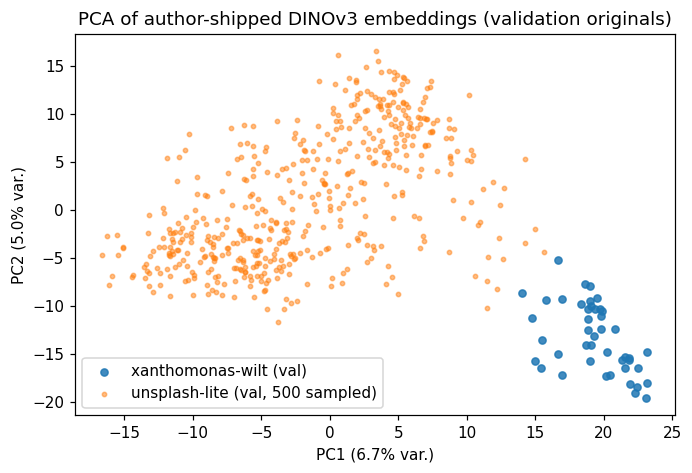

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)            # deterministic OOD subsample for scoring/plots
N_UL_SCORED = 500
ul_scored_idx = np.sort(rng.choice(ul_val_idx, size=N_UL_SCORED, replace=False))

X = np.vstack([mm_xw[xw_val_idx], mm_ul[ul_scored_idx]]).astype(np.float64)
Xz = (X - X.mean(0)) / X.std(0)
U, S, Vt = np.linalg.svd(Xz, full_matrices=False)
pcs = U[:, :2] * S[:2]
share = S[:2] ** 2 / np.sum(S ** 2)

fig, ax = plt.subplots(figsize=(6.4, 4.4), dpi=110)
ax.scatter(pcs[:len(xw_val_idx), 0], pcs[:len(xw_val_idx), 1], s=22, label="xanthomonas-wilt (val)", alpha=0.85)
ax.scatter(pcs[len(xw_val_idx):, 0], pcs[len(xw_val_idx):, 1], s=8, label=f"unsplash-lite (val, {N_UL_SCORED} sampled)", alpha=0.5)
ax.set_xlabel(f"PC1 ({share[0]:.1%} var.)"); ax.set_ylabel(f"PC2 ({share[1]:.1%} var.)")
ax.set_title("PCA of author-shipped DINOv3 embeddings (validation originals)")
ax.legend(); fig.tight_layout(); plt.show()

## 3 · Rebuild the flow and load the released checkpoint

The author notebook constructs the model once (`zuko.flows.NSF(384*3, 8, transforms=8, hidden_features=[1280,1280], activation=nn.SiLU)` — 8 rational-quadratic-spline transforms by default) and loads the TPU-side `xser` checkpoint (`models/bdd_model.pt`). That serialization (verified against `torch_xla` v2.9.0 `utils/serialization.py`) stores each tensor as a plain `torch.save` file under `models/bdd_model.pt.tensors/tensor_{tid}.pt`, with `TensorReference(tid)` stubs in the main zip. `xser.load` itself needs `torch_xla`, so the cell below is an **AI-generated CPU-compatible loader** that follows that exact file format (stub module + recursive replacement); it replaces only the loading mechanism, not any numerical operation.

日本語: 著者と同一の構成でフローを再構築し、公開チェックポイントを読み込みます。xser形式（本体zip＋外部テンソルファイル）をCPUで読む小さなアダプタはAI生成ですが、ファイル形式そのものは torch_xla v2.9.0 の実装に準拠しています。

In [ ]:
import sys, types

class _TensorReference:
    def __init__(self, tid):
        self.tid = tid

def xser_load_cpu(path):
    """CPU loader for torch_xla.utils.serialization external-tensor checkpoints.

    Format per pytorch/xla v2.9.0 torch_xla/utils/serialization.py:
    main zip holds TensorReference(tid) stubs; payloads at <path>.tensors/tensor_{tid}.pt.
    AI-generated adapter (mechanism only; identical file format and values).
    Unpickling requires the stub's *parent packages* to be importable too, so we
    register torch_xla and torch_xla.utils as namespace-package stubs.
    """
    for name in ("torch_xla", "torch_xla.utils"):
        if name not in sys.modules:
            pkg = types.ModuleType(name)
            pkg.__path__ = []                     # namespace package stub
            sys.modules[name] = pkg
    stubmod = types.ModuleType("torch_xla.utils.serialization")
    stubmod.TensorReference = _TensorReference
    sys.modules["torch_xla.utils.serialization"] = stubmod
    ref = torch.load(path, weights_only=False)
    folder = pathlib.Path(f"{path}.tensors")

    def walk(v):
        if isinstance(v, _TensorReference):
            return torch.load(folder / f"tensor_{v.tid}.pt", weights_only=True, map_location="cpu")
        if isinstance(v, dict):
            return {k: walk(x) for k, x in v.items()}
        if isinstance(v, (list, tuple)):
            return type(v)(walk(x) for x in v)
        return v

    return walk(ref)

flow_model = zuko.flows.NSF(384 * 3, 8, transforms=8, hidden_features=[1280, 1280],
                            activation=nn.SiLU).to(device)   # author notebook, cell 16
state = xser_load_cpu(f"{REPO_DIR}/models/bdd_model.pt")
flow_model.load_state_dict(state)                            # strict: key/shape mismatch would raise
flow_model.eval()

n_params = sum(p.numel() for p in flow_model.parameters())
print("flow parameters:", f"{n_params:,}")
assert n_params == 296_537_088, "parameter count does not match paper Table 3"
CHECKPOINT_LOADED = True   # guard: downstream cells refuse to score with an untrained model
print("checkpoint loaded strictly; parameter count matches paper Table 3.")

flow parameters: 296,537,088
checkpoint loaded strictly; parameter count matches paper Table 3.


### Score the samples under all eight class conditions

Exactly the author's evaluation pattern (notebook cell 22): each embedding is tiled against all eight one-hot class conditions and scored by `flow_model(labels).log_prob(targets)`, giving one conditional log-likelihood per class. Inference runs in float32 on the selected device (the authors' bfloat16 autocast was a TPU training detail). We score all `xanthomonas-wilt` validation originals and the deterministic 500-sample `unsplash-lite` subset chosen above. The `CHECKPOINT_LOADED` guard fails the cell loudly if the checkpoint was not loaded, so a silent fall-back to the randomly initialized flow is impossible.

日本語: 著者セル22と同一の方法で、各埋め込みを8クラス条件すべてに対して評価し、クラス条件付き対数尤度を得ます。チェックポイント読込に失敗した場合はここで停止します。

In [ ]:
import torch

assert CHECKPOINT_LOADED, "checkpoint was not loaded; refusing to score with an untrained flow"

CLASS_NAMES = ["xanthomonas-wilt", "bunchy-top", "yellow-sigatoka", "black-sigatoka",
               "fusarium-wilt", "healthy", "plantnet", "unsplash-lite"]  # author class_meta order
DISEASES, HEALTHY = slice(0, 5), 5
BANANA, NON_BANANA = slice(0, 6), slice(6, 8)

def class_conditional_ll(lats):
    lats = torch.as_tensor(np.asarray(lats), dtype=torch.float32, device=device)
    n = lats.shape[0]
    targets = lats[:, None, :].tile(1, 8, 1)                      # [n, 8, 1152]
    weights = torch.eye(8, device=device)[None].tile(n, 1, 1)     # [n, 8, 8] one-hot conditions
    with torch.no_grad():
        dist = flow_model(weights)
        return dist.log_prob(targets).cpu()                       # [n, 8]

ll_xw = class_conditional_ll(mm_xw[xw_val_idx])
ll_ul = class_conditional_ll(mm_ul[ul_scored_idx])
print("conditional log-likelihoods:", ll_xw.shape, ll_ul.shape, "| finite:", bool(torch.isfinite(ll_xw).all() and torch.isfinite(ll_ul).all()))

conditional log-likelihoods: torch.Size([44, 8]) torch.Size([500, 8]) | finite: True


### Classification check — does argmax-likelihood recover the true class?

The paper assigns each image the class with the highest conditional log likelihood (§3.2; 97.6% test accuracy over all classes). On our small validation sample we can check the plausibility of that rule: the modal predicted class of the XW validation originals should be `xanthomonas-wilt`, with residual confusion concentrated in the symptomatically related Sigatoka classes, as the paper reports.

日本語: 尤度最大のクラスが正解クラス（XW）に一致するかを確認します。論文どおり、混同は黄色・黒シガトカ等の症状類似クラスに集中するはずです。

In [ ]:
pred_xw = [CLASS_NAMES[i] for i in ll_xw.argmax(-1).tolist()]
pred_counts = pd.Series(pred_xw).value_counts().rename("predicted (of 8 classes)")
display(pred_counts.to_frame())

acc_xw = float(np.mean(np.array(pred_xw) == "xanthomonas-wilt"))
print(f"argmax-likelihood accuracy on {len(xw_val_idx)} XW validation originals: {acc_xw:.1%}")
print("(paper reference: 97.6% 8-class accuracy on the independent test set — not directly comparable)")

,predicted (of 8 classes)
xanthomonas-wilt,35
yellow-sigatoka,4
black-sigatoka,3
healthy,2


argmax-likelihood accuracy on 44 XW validation originals: 79.5%
(paper reference: 97.6% 8-class accuracy on the independent test set — not directly comparable)


### The two likelihood ratios

From the paper (§3.3, Figs. 10 & 12): the **disease ratio** compares each disease class against healthy banana, and the **plant ratio** compares banana classes against the two non-banana reference classes (`plantnet`, `unsplash-lite`). The prose does not pin the reduction over classes, so as a documented adaptation we use the **maximum** conditional log-likelihood within each side:

- disease LLR = max over the 5 disease classes − LL(healthy)
- plant LLR = max over the 6 banana classes − max over the 2 non-banana references

Positive values favour the numerator hypothesis. Expect XW validation originals to sit at positive disease and plant ratios, and the Unsplash Lite sample to fall to a negative plant ratio (the paper's out-of-distribution region) regardless of its disease score.

日本語: 論文は「各病害クラス対ヘルシー」「バナナ類対非バナナ参照」を定義しますが、クラス集合の集約方法（最大値か平均か）は明示していません。そこで最大値集約を採用したことを明記します（本Notebookの適応）。

Reference values for context (paper Table 5, independent test set): XW F1 0.9878, AvPr 0.9678, AUROC 0.9967 on 44 test images — our 41-image validation sample is a plausibility check only, not an equivalence test.

In [ ]:
disease_llr_xw = (ll_xw[:, DISEASES].max(-1).values - ll_xw[:, HEALTHY])   # [n_xw]
disease_llr_ul = (ll_ul[:, DISEASES].max(-1).values - ll_ul[:, HEALTHY])
plant_llr_xw = ll_xw[:, BANANA].max(-1).values - ll_xw[:, NON_BANANA].max(-1).values
plant_llr_ul = ll_ul[:, BANANA].max(-1).values - ll_ul[:, NON_BANANA].max(-1).values

per_disease_xw = ll_xw[:, :5] - ll_xw[:, [5]]                              # each disease vs healthy
summary = pd.DataFrame({
    "quantity": ["mean disease LLR (max over diseases)", "mean plant LLR (banana vs non-banana)"],
    "xanthomonas-wilt (val)": [disease_llr_xw.mean().item(), plant_llr_xw.mean().item()],
    f"unsplash-lite (val, n={N_UL_SCORED})": [disease_llr_ul.mean().item(), plant_llr_ul.mean().item()],
})
display(summary.round(3))

pd.DataFrame(per_disease_xw.numpy(), columns=[f"LLR {c} vs healthy" for c in CLASS_NAMES[:5]]
             ).describe().loc[["mean", "25%", "75%"]].round(3)

,quantity,xanthomonas-wilt (val),"unsplash-lite (val, n=500)"
0,mean disease LLR (max over diseases),24.190,-1.627
1,mean plant LLR (banana vs non-banana),171.109,-97.249


,LLR xanthomonas-wilt vs healthy,LLR bunchy-top vs healthy,LLR yellow-sigatoka vs healthy,LLR black-sigatoka vs healthy,LLR fusarium-wilt vs healthy
mean,23.011,-16.466,6.979,6.481,-10.218
25%,13.323,-23.621,-0.128,0.557,-15.545
75%,31.431,-8.025,13.307,10.937,-2.681


### 2-D diagnostic space (paper Fig. 12 analogue)

The joint space of the two ratios separates confident disease detections (upper-right), healthy/ambiguous regions near the origin, and out-of-distribution imagery (negative plant ratio). Here the two validation sets play exactly those roles. This is a reproduction of the paper's diagnostic-space construction on a two-class sample — not Figure 12 itself.

日本語: 論文Fig.12の構成に従い、横軸に植物比・縦軸に病害比を取った2次元診断空間を描きます。XWは右上（確信的な検出）、Unsplash Liteは植物比が負のOOD領域に分布するはずです。

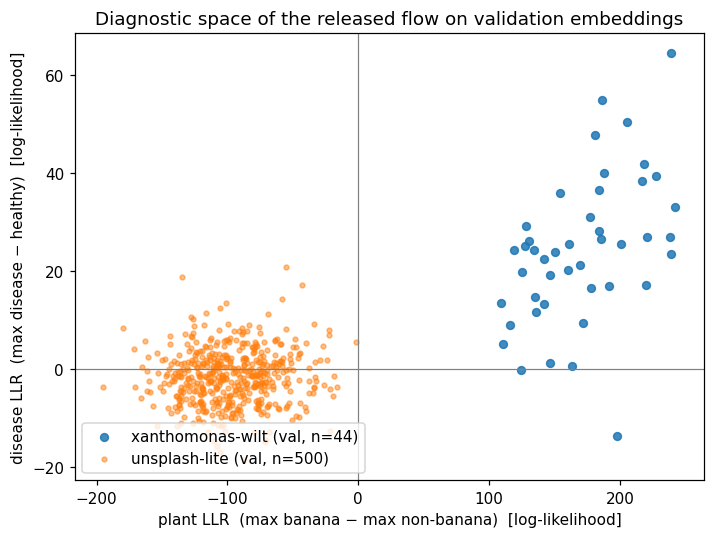

In [ ]:
fig, ax = plt.subplots(figsize=(6.6, 5.0), dpi=110)
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.scatter(plant_llr_xw.numpy(), disease_llr_xw.numpy(), s=26, alpha=0.85,
           label=f"xanthomonas-wilt (val, n={len(xw_val_idx)})")
ax.scatter(plant_llr_ul.numpy(), disease_llr_ul.numpy(), s=10, alpha=0.5,
           label=f"unsplash-lite (val, n={N_UL_SCORED})")
ax.set_xlabel("plant LLR  (max banana − max non-banana)  [log-likelihood]")
ax.set_ylabel("disease LLR  (max disease − healthy)  [log-likelihood]")
ax.set_title("Diagnostic space of the released flow on validation embeddings")
ax.legend(loc="lower left")
fig.tight_layout(); plt.show()

### Export the per-image results

A small CSV in `/content` with the eight conditional log-likelihoods and both ratios per scored embedding, for inspection beyond the plots.

日本語: 8クラスの対数尤度と2つの尤度比をCSVに書き出します。

In [ ]:
rows = []
for label, idxs, ll, dlr, plr in [
    ("xanthomonas-wilt", xw_val_idx, ll_xw, disease_llr_xw, plant_llr_xw),
    ("unsplash-lite", ul_scored_idx, ll_ul, disease_llr_ul, plant_llr_ul),
]:
    df = pd.DataFrame(ll.numpy(), columns=[f"ll:{c}" for c in CLASS_NAMES])
    df.insert(0, "label", label)
    df.insert(1, "metadata_index", idxs)
    df["disease_llr"] = dlr.numpy()
    df["plant_llr"] = plr.numpy()
    rows.append(df)
results = pd.concat(rows, ignore_index=True)
results.to_csv("/content/bdd_llr_results.csv", index=False)
print(f"wrote /content/bdd_llr_results.csv ({len(results)} rows)")
display(results.head(3).round(3))

wrote /content/bdd_llr_results.csv (544 rows)


,label,metadata_index,ll:xanthomonas-wilt,ll:bunchy-top,ll:yellow-sigatoka,ll:black-sigatoka,ll:fusarium-wilt,ll:healthy,ll:plantnet,ll:unsplash-lite,disease_llr,plant_llr
0,xanthomonas-wilt,1200,1734.630981,1678.995972,1728.208984,1736.640015,1715.780029,1712.431030,1390.234985,1602.375977,24.209000,134.264008
1,xanthomonas-wilt,1700,1773.727051,1717.515991,1752.975952,1750.203003,1738.906006,1737.177002,1483.130005,1589.911011,36.549999,183.815994
2,xanthomonas-wilt,2400,1752.738037,1704.387939,1743.364014,1731.213989,1713.318970,1727.387939,1538.355957,1591.354980,25.351000,161.384003


## Interpretation and limitations

**What was executed (CPU, fresh Colab runtime):** the authors' released conditional flow was rebuilt per Table 3, their `xser` checkpoint was loaded strictly (parameter count matching the paper's 296,537,088), and validation-split embeddings of *Xanthomonas Wilt* and *Unsplash Lite* were scored under all eight class conditions, reproducing the argmax-likelihood classification rule and the paper's two likelihood ratios on a two-class sample.

**What this does not establish:** dataset-level metrics (paper: 97.6% 8-class accuracy; XW F1 0.9878 / AvPr 0.9678 / AUROC 0.9967 on 44 test images), calibration (temperature T = 5.2), image-level extraction/inference, or any training. The likelihood-ratio **reduction over classes is an adaptation** (paper prose pins the comparisons but not the aggregation; max was used). Only single-part classes were used because the author code concatenates multi-part classes in arbitrary `os.listdir` order, making metadata `index` ambiguous there.

**Provenance:** paper DOI 10.3389/fpls.2026.1937900 (Frontiers OA, Version of Record 2026-10-09); author repository commit `6ac051f1e2a5ea280a74bc647b499bee1dd7e1ae` (LGPL-2.1); payload SHA-256s from the pinned LFS pointers, verified after download; the CPU `xser` loader and the ratio reduction are AI-generated adaptations, cited in their cells. PhenoPaper investigation `p-14ff09b4c742a4f8ef71bf83c2d975e0-20261021T062028Z-1929087` was used as prior research guidance only.

日本語: 本Notebookは公開済みチェックポイントとキャッシュ埋め込みによる**推論の部分再現**であり、論文のデータセット全体の精度や較正、学習は検証していません。尤度比のクラス集約（最大値）は本Notebookの適応です。